# Engineering Beam Modes

Run all cells in your OneSimulation environment. The recorded output below was generated by executing this code. The spatial view uses the solved forces, eigenvectors or stress tensor.

2 elements [Hz] [  8.386   52.9742 179.1685]
16 elements [Hz] [  8.3819  52.5288 147.0871]
analytical [Hz] [  8.3819  52.5285 147.0813]


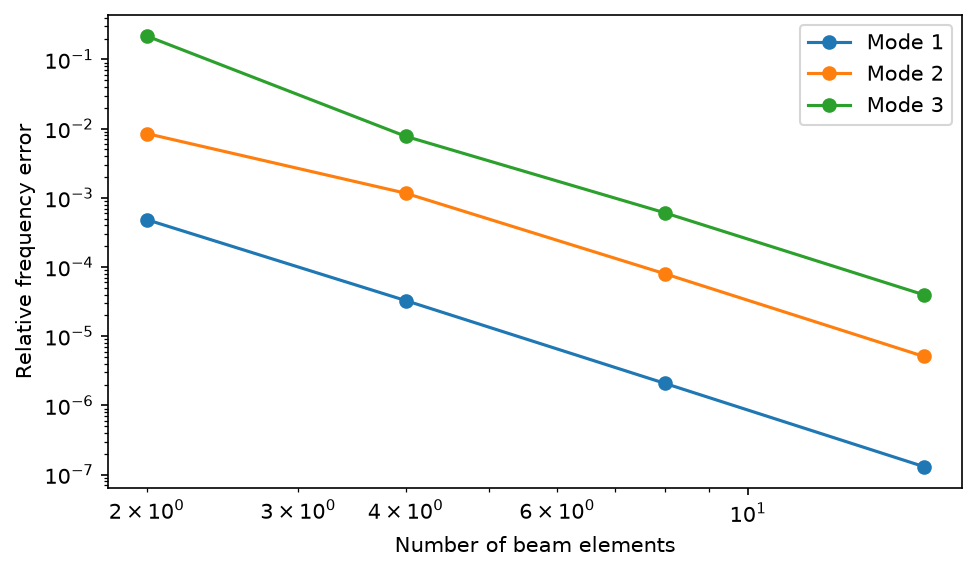

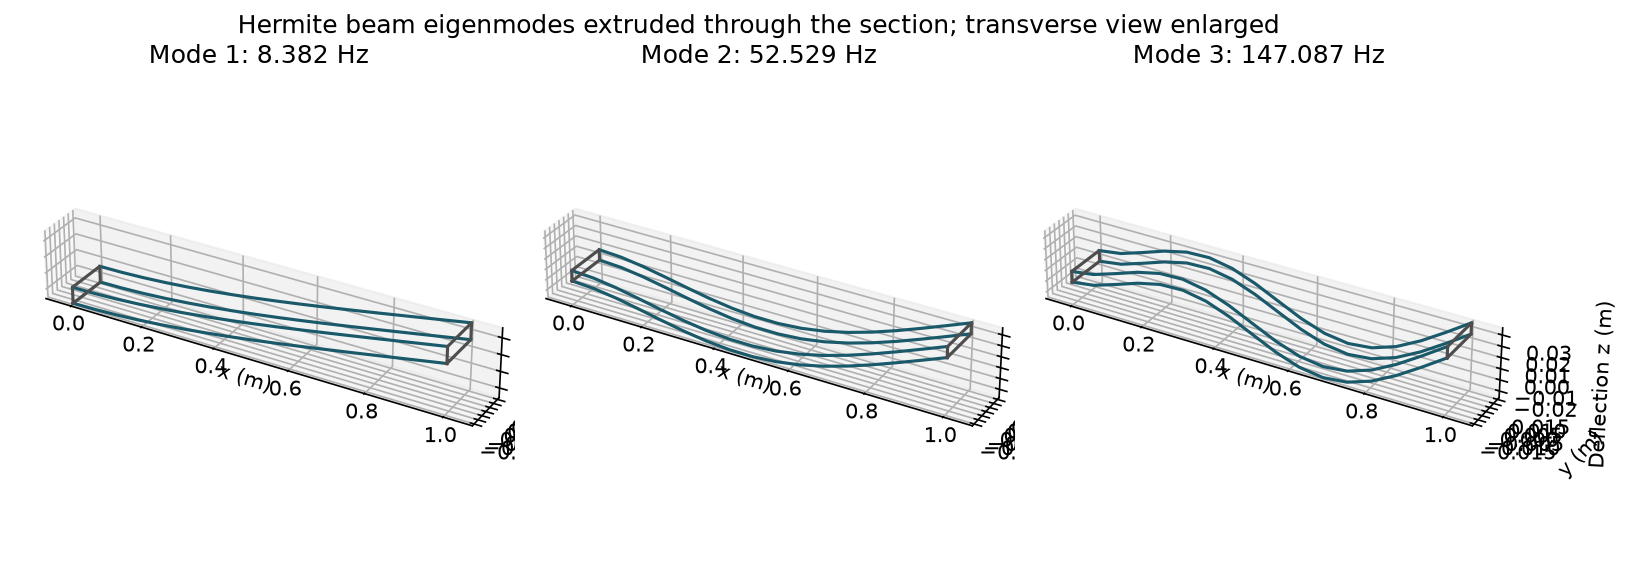

In [1]:
"""Assemble a cantilever from Hermite elements; validate its first three modes."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear import SparseSymmetricEigenSolver

length, width, depth = 1.0, 0.03, 0.01  # m
E, density = 210e9, 7800.0
area, inertia = width*depth, width*depth**3/12

def beam_frequencies(elements, return_modes=False):
    h = length/elements
    k = E*inertia/h**3*np.array([[12,6*h,-12,6*h],[6*h,4*h*h,-6*h,2*h*h],
                                 [-12,-6*h,12,-6*h],[6*h,2*h*h,-6*h,4*h*h]])
    m = density*area*h/420*np.array([[156,22*h,54,-13*h],[22*h,4*h*h,13*h,-3*h*h],
                                    [54,13*h,156,-22*h],[-13*h,-3*h*h,-22*h,4*h*h]])
    size = 2*(elements+1)
    mass, stiffness = np.zeros((size,size)), np.zeros((size,size))
    for element in range(elements):
        dofs = np.arange(2*element,2*element+4)
        mass[np.ix_(dofs,dofs)] += m
        stiffness[np.ix_(dofs,dofs)] += k
    values, modes = SparseSymmetricEigenSolver()(mass[2:,2:], stiffness[2:,2:],
                                                 mode_count=3, target=0.0)
    assert np.allclose(modes.T @ mass[2:,2:] @ modes, np.eye(3), atol=1e-8)
    return (np.sqrt(values)/(2*np.pi), modes) if return_modes else np.sqrt(values)/(2*np.pi)

beta = np.array([1.875104069,4.694091133,7.854757438])
exact = beta**2*np.sqrt(E*inertia/(density*area))/(2*np.pi*length**2)
counts = [2, 4, 8, 16]
frequencies = np.array([beam_frequencies(count) for count in counts])
print("2 elements [Hz]", np.round(frequencies[0], 4))
print("16 elements [Hz]", np.round(frequencies[-1], 4))
print("analytical [Hz]", np.round(exact, 4))
fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
for mode in range(3):
    ax.loglog(counts, abs(frequencies[:,mode]/exact[mode]-1), "o-", label=f"Mode {mode+1}")
ax.set(xlabel="Number of beam elements", ylabel="Relative frequency error")
ax.legend()
plt.show()

# The 3D drawing uses the actual discrete OneSimulation eigenvectors.
frequencies_3d, modes_3d = beam_frequencies(16, return_modes=True)
coordinates = np.linspace(0,length,17)
fig = plt.figure(figsize=(10,3.8), layout="constrained")
for index in range(3):
    ax = fig.add_subplot(1,3,index+1,projection="3d")
    displacement = np.r_[0., modes_3d[::2,index]]
    displacement *= 0.03/displacement[-1]  # chosen signed tip amplitude, m
    for side in [-1,1]:
        for vertical in [-1,1]:
            ax.plot(coordinates, np.full_like(coordinates,side*width/2),
                    displacement+vertical*depth/2,color="#19596a")
    for station in [0,16]:
        ax.plot([coordinates[station]]*5,[-width/2,width/2,width/2,-width/2,-width/2],
                displacement[station]+np.array([-depth/2,-depth/2,depth/2,depth/2,-depth/2]),color="0.3")
    ax.set(xlabel="x (m)",ylabel="y (m)",zlabel="Deflection z (m)",
           title=f"Mode {index+1}: {frequencies_3d[index]:.3f} Hz")
    ax.set_box_aspect((1,.12,.16))
fig.suptitle("Hermite beam eigenmodes extruded through the section; transverse view enlarged")
plt.show()
